<a href="https://colab.research.google.com/github/samritha07/Deep-Learning/blob/main/DL_EXP_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# EXPERIMENT NO: 8
# GENERATION OF SYNTHETIC IMAGES USING GAN
# NAME: SAMRITHA S
# ROLL NO: 24BAD103

# TASK A1: Import Required Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import os

from tensorflow.keras import layers, Sequential
from sklearn.decomposition import PCA

print("Name: SAMRITHA S")
print("Roll No: 24BAD103")
print("Libraries Imported Successfully")

Name: SAMRITHA S
Roll No: 24BAD103
Libraries Imported Successfully


In [2]:
# TASK A2: Initialize GAN Parameters

np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

IMG_SIZE = 28
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 20

print("Image Size:", IMG_SIZE)
print("Latent Dimension:", LATENT_DIM)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Image Size: 28
Latent Dimension: 100
Batch Size: 128
Epochs: 20


In [3]:
# TASK A3: Load the MNIST Dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training Images Shape:", x_train.shape)
print("Testing Images Shape:", x_test.shape)
print("Training Labels Shape:", y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images Shape: (60000, 28, 28)
Testing Images Shape: (10000, 28, 28)
Training Labels Shape: (60000,)


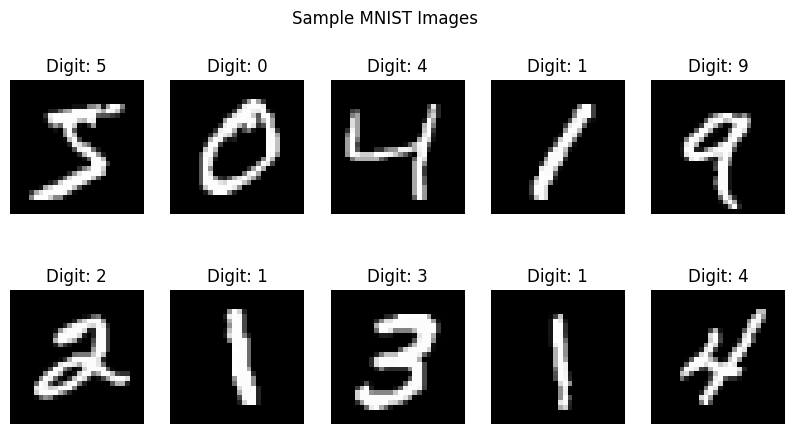

In [4]:
# TASK A4: Display Sample Images from the Dataset

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')

plt.suptitle("Sample MNIST Images")
plt.show()

In [5]:
# TASK A5: Explore Image Dimensions and Pixel Values

print("Image Dimensions:", x_train[0].shape)
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())
print("Data Type:", x_train.dtype)

Image Dimensions: (28, 28)
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Data Type: uint8


In [6]:
# TASK A6: Normalize and Reshape Images

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

x_train = (x_train - 127.5) / 127.5
x_test = (x_test - 127.5) / 127.5

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)
print("Minimum Value:", x_train.min())
print("Maximum Value:", x_train.max())

Training Shape: (60000, 28, 28, 1)
Testing Shape: (10000, 28, 28, 1)
Minimum Value: -1.0
Maximum Value: 1.0


In [7]:
# TASK A7: Prepare Batches of Real Images for Training

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = train_dataset.shuffle(60000).batch(
    BATCH_SIZE, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

print("Dataset Batching Completed")
print("Number of Batches:", len(train_dataset))

Dataset Batching Completed
Number of Batches: 468


In [8]:
# TASK B1: Build the Generator Model

generator = Sequential([
    layers.Input(shape=(LATENT_DIM,)),
    layers.Dense(7 * 7 * 128),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Reshape((7, 7, 128)),

    layers.Conv2DTranspose(64, 4, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2DTranspose(32, 4, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.2),

    layers.Conv2D(1, 3, padding='same', activation='tanh')
], name="Generator")

generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 823,169 (3.14 MB)

 Trainable params: 810,433 (3.09 MB)

 Non-trainable params: 12,736 (49.75 KB)

Generated Image Shape: (1, 28, 28, 1)


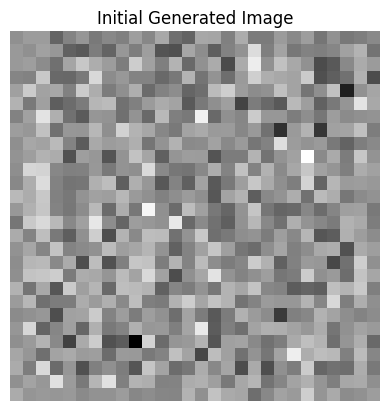

In [9]:
# TASK B2: Generate an Image Using Random Noise

noise = tf.random.normal([1, LATENT_DIM])

generated_image = generator(noise, training=False)

print("Generated Image Shape:", generated_image.shape)

plt.imshow(generated_image[0, :, :, 0], cmap='gray')
plt.title("Initial Generated Image")
plt.axis('off')
plt.show()

In [10]:
# TASK B3: Build the Discriminator Model

discriminator = Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(64, 4, strides=2, padding='same'),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Conv2D(128, 4, strides=2, padding='same'),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1, activation='sigmoid')
], name="Discriminator")

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# TASK B4: Classify Generated Images Using Discriminator

prediction = discriminator(generated_image)

print("Discriminator Prediction:", prediction.numpy())
print("Output Shape:", prediction.shape)

Discriminator Prediction: [[0.50040716]]
Output Shape: (1, 1)


In [12]:
# TASK B5: Select Loss Functions and Optimizers

cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )

    return real_loss + fake_loss

print("Loss Functions and Optimizers Initialized")

Loss Functions and Optimizers Initialized


In [24]:
# TASK C1: Train the Generator and Discriminator

@tf.function
def train_step(real_images):

    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = generator_loss(fake_output)
        d_loss = discriminator_loss(real_output, fake_output)

    g_gradients = gen_tape.gradient(
        g_loss, generator.trainable_variables
    )

    d_gradients = disc_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss

print("GAN Training Function Created Successfully")

GAN Training Function Created Successfully


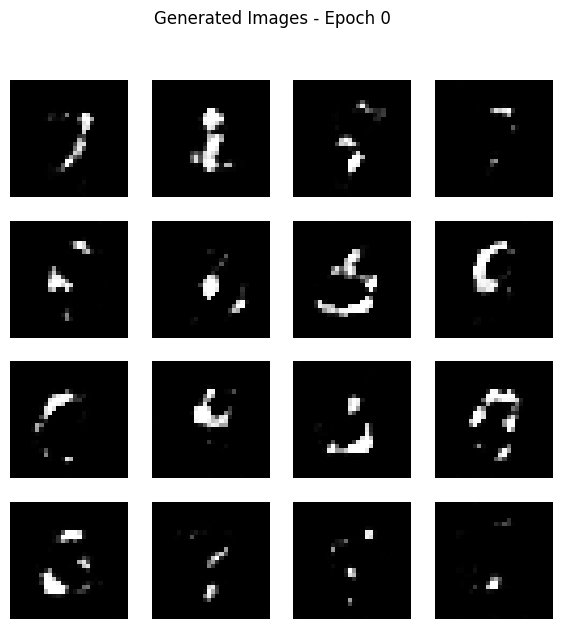

In [25]:
# TASK C2: Display Sample Generated Images

fixed_noise = tf.random.normal([16, LATENT_DIM])

def display_generated_images(epoch):

    images = generator(fixed_noise, training=False)
    images = (images + 1) / 2

    plt.figure(figsize=(7, 7))

    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(images[i, :, :, 0], cmap='gray')
        plt.axis('off')

    plt.suptitle("Generated Images - Epoch " + str(epoch))
    plt.show()

display_generated_images(0)

Epoch: 1
Generator Loss: 0.7623
Discriminator Loss: 1.3114


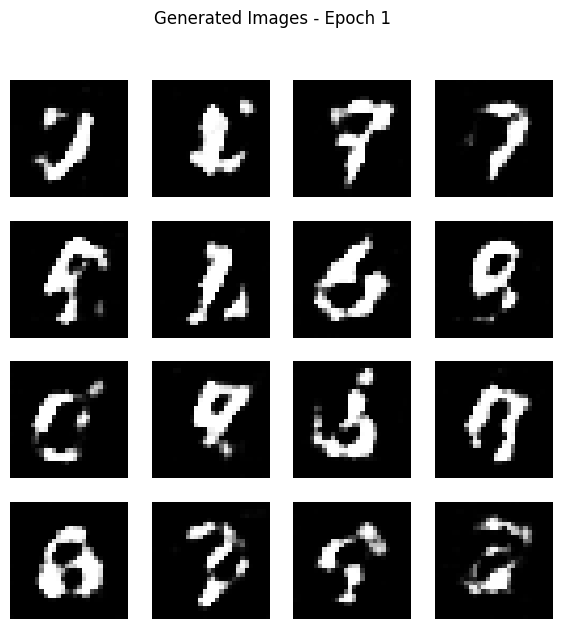

Epoch: 2
Generator Loss: 0.774
Discriminator Loss: 1.2948


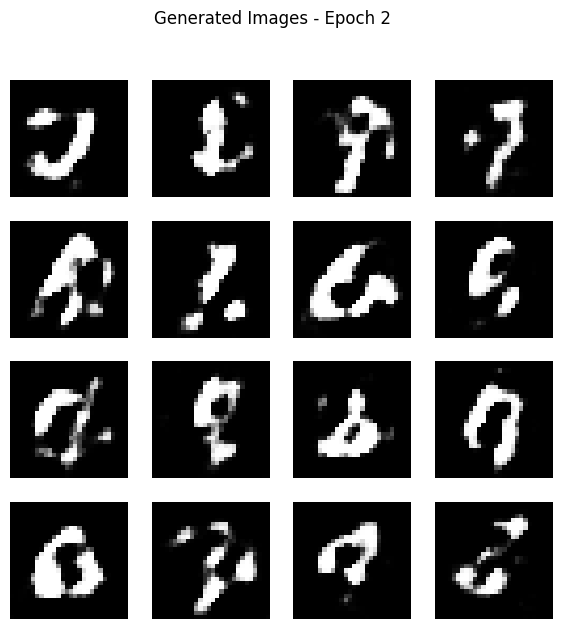

Epoch: 3
Generator Loss: 0.8036
Discriminator Loss: 1.2707


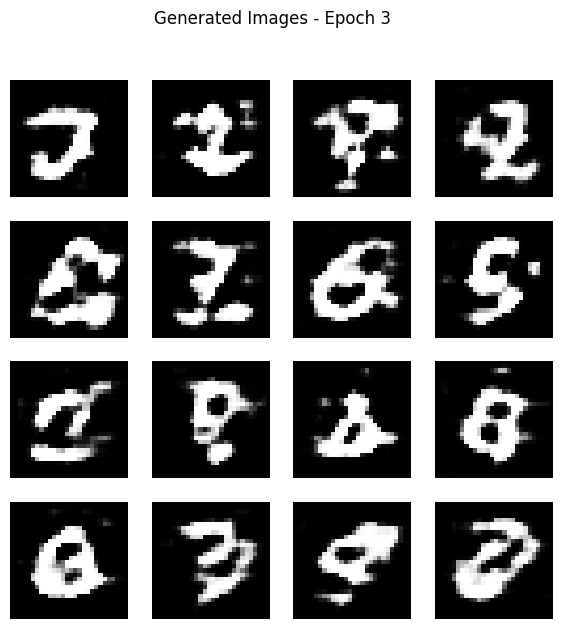

Epoch: 4
Generator Loss: 0.8268
Discriminator Loss: 1.2409


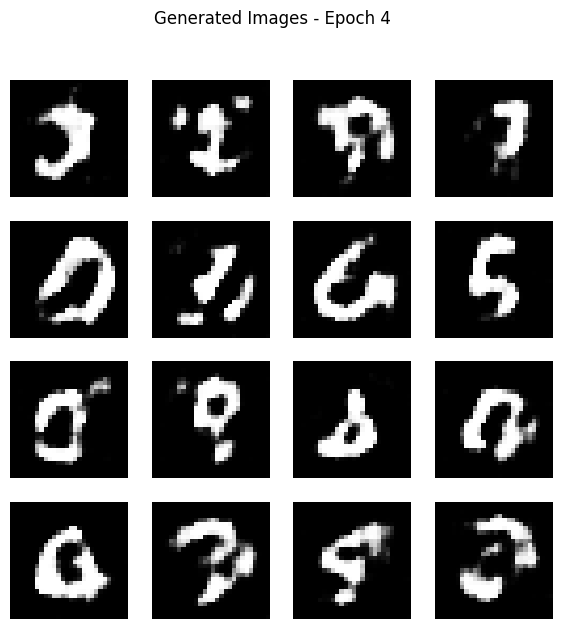

Epoch: 5
Generator Loss: 0.837
Discriminator Loss: 1.2423


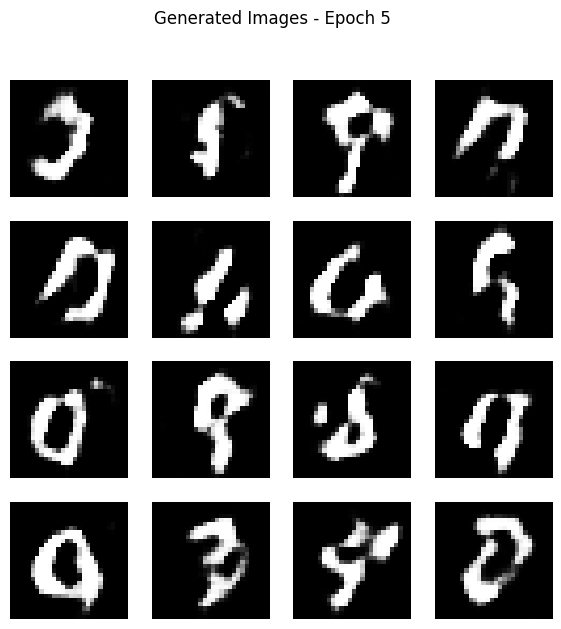

GAN Training Completed Successfully


In [26]:
# TASK C3: Train GAN Using a Smaller Dataset

generator_losses = []
discriminator_losses = []

EPOCHS = 5

# Use only 10,000 training images
small_dataset = tf.data.Dataset.from_tensor_slices(x_train[:10000])

small_dataset = small_dataset.shuffle(10000).batch(
    BATCH_SIZE, drop_remainder=True
).prefetch(tf.data.AUTOTUNE)

for epoch in range(1, EPOCHS + 1):

    g_total = 0
    d_total = 0
    count = 0

    for batch in small_dataset:

        g_loss, d_loss = train_step(batch)

        g_total += float(g_loss)
        d_total += float(d_loss)
        count += 1

    avg_g_loss = g_total / count
    avg_d_loss = d_total / count

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    print("Epoch:", epoch)
    print("Generator Loss:", round(avg_g_loss, 4))
    print("Discriminator Loss:", round(avg_d_loss, 4))

    display_generated_images(epoch)

print("GAN Training Completed Successfully")

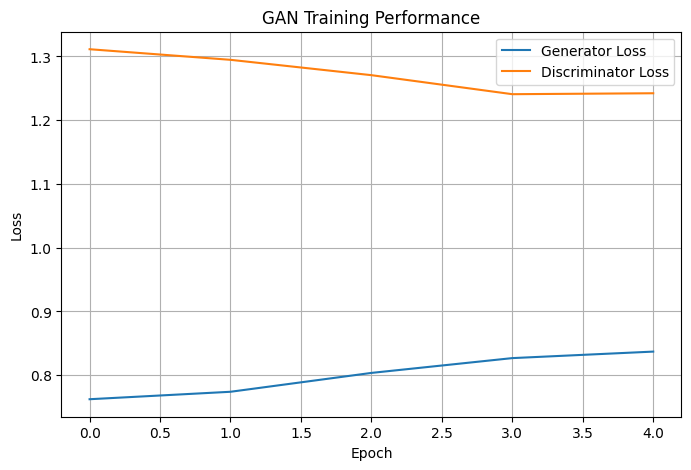

In [27]:
# TASK C4: Plot Generator and Discriminator Losses

plt.figure(figsize=(8, 5))

plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Performance")
plt.legend()
plt.grid()
plt.show()

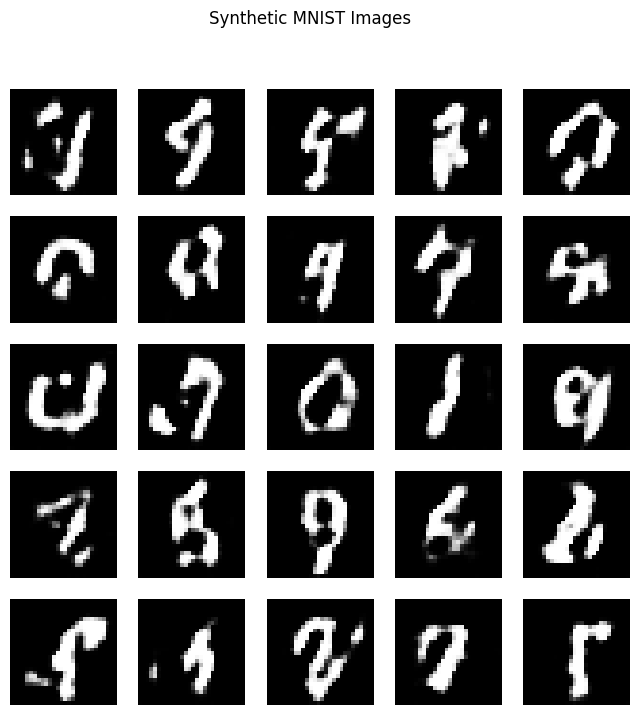

25 Synthetic Images Generated Successfully


In [29]:
# TASK C5: Generate Synthetic Images

noise = tf.random.normal([25, LATENT_DIM])

synthetic_images = generator(noise, training=False)

synthetic_images = (synthetic_images + 1) / 2

plt.figure(figsize=(8, 8))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(synthetic_images[i, :, :, 0], cmap='gray')
    plt.axis('off')

plt.suptitle("Synthetic MNIST Images")
plt.show()

print("25 Synthetic Images Generated Successfully")

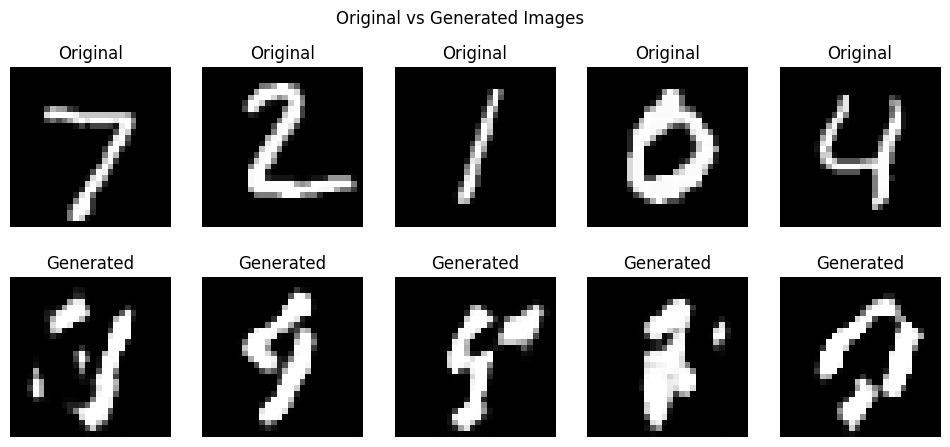

In [30]:
# TASK D1: Compare Generated Images with Original Dataset Samples

plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i, :, :, 0], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(synthetic_images[i, :, :, 0], cmap='gray')
    plt.title("Generated")
    plt.axis('off')

plt.suptitle("Original vs Generated Images")
plt.show()

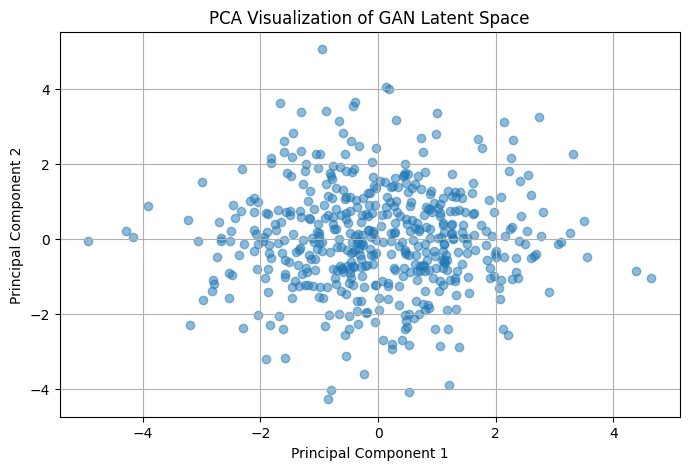

Original Dimensions: (500, 100)
Reduced Dimensions: (500, 2)


In [31]:
# TASK D2: Extract Latent-Space Representations

latent_vectors = tf.random.normal([500, LATENT_DIM]).numpy()

pca = PCA(n_components=2)
latent_reduced = pca.fit_transform(latent_vectors)

plt.figure(figsize=(8, 5))

plt.scatter(
    latent_reduced[:, 0],
    latent_reduced[:, 1],
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of GAN Latent Space")
plt.grid(True)
plt.show()

print("Original Dimensions:", latent_vectors.shape)
print("Reduced Dimensions:", latent_reduced.shape)

In [33]:
# TASK D3: Extract Features Using the Trained Discriminator

# Build the Discriminator by passing a sample image
dummy_input = tf.zeros((1, 28, 28, 1))
discriminator(dummy_input)

# Create feature extractor
feature_extractor = tf.keras.Model(
    inputs=discriminator.inputs,
    outputs=discriminator.layers[-2].output
)

# Select real images
real_samples = x_test[:500]

# Generate fake images
noise = tf.random.normal([500, LATENT_DIM])
fake_samples = generator(noise, training=False)

# Extract real image features
real_features = feature_extractor(
    real_samples, training=False
).numpy()

# Extract generated image features
fake_features = feature_extractor(
    fake_samples, training=False
).numpy()

print("Real Feature Shape:", real_features.shape)
print("Generated Feature Shape:", fake_features.shape)

print("Feature Extraction Completed Successfully")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(500, 28, 28, 1))
  warnings.warn(msg)


Real Feature Shape: (500, 6272)
Generated Feature Shape: (500, 6272)
Feature Extraction Completed Successfully


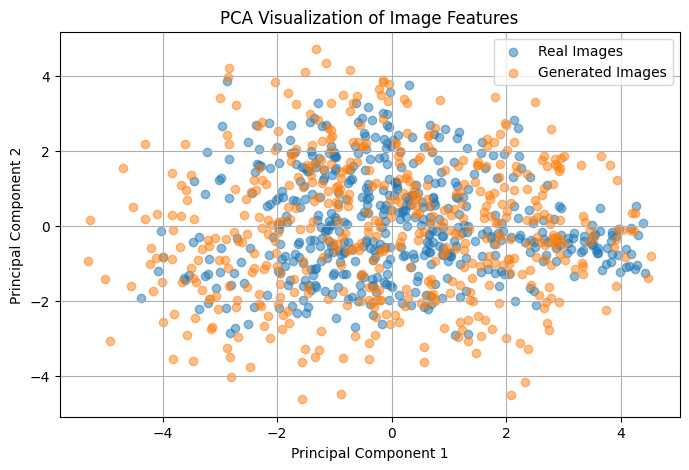

Feature Visualization Completed


In [34]:
# TASK D4: Perform Dimensionality Reduction and Feature Visualization

combined_features = np.concatenate(
    [real_features, fake_features], axis=0
)

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(combined_features)

plt.figure(figsize=(8, 5))

plt.scatter(
    reduced_features[:500, 0],
    reduced_features[:500, 1],
    label='Real Images',
    alpha=0.5
)

plt.scatter(
    reduced_features[500:, 0],
    reduced_features[500:, 1],
    label='Generated Images',
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Image Features")
plt.legend()
plt.grid(True)
plt.show()

print("Feature Visualization Completed")

In [35]:
# TASK D5: Save the Trained Generator and Discriminator Models

generator.save("GAN_Generator.keras")
discriminator.save("GAN_Discriminator.keras")

print("Generator Model Saved Successfully")
print("Discriminator Model Saved Successfully")

Generator Model Saved Successfully
Discriminator Model Saved Successfully


In [36]:
# TASK D6: Download the Trained Models

from google.colab import files

files.download("GAN_Generator.keras")
files.download("GAN_Discriminator.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# TASK D7: Document the Experiment Results

print("GENERATION OF SYNTHETIC IMAGES USING GAN")
print("----------------------------------------")

print("Student Name:", "SAMRITHA S")
print("Roll Number:", "24BAD103")
print("Dataset: MNIST")
print("Model: Deep Convolutional GAN")
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Latent Dimension:", LATENT_DIM)
print("Synthetic Images Generated:", 25)

print("Generator Final Loss:", generator_losses[-1])
print("Discriminator Final Loss:", discriminator_losses[-1])

print("Experiment Completed Successfully")

GENERATION OF SYNTHETIC IMAGES USING GAN
----------------------------------------
Student Name: SAMRITHA S
Roll Number: 24BAD103
Dataset: MNIST
Model: Deep Convolutional GAN
Epochs: 5
Batch Size: 128
Latent Dimension: 100
Synthetic Images Generated: 25
Generator Final Loss: 0.837005982032189
Discriminator Final Loss: 1.2423181105882695
Experiment Completed Successfully
